# Investigation of Hospital Length of Stay
- Author: Sydney Sailors
- Date: 2026-11-09

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned MEPS dataset
df = pd.read_csv("../data/processed/meps_los_clean.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1912, 20)


,DUPERSID,NUMNIGHX,EMERROOM,RSNINHOS,ANYOPER,IPXP24X,IPTC24X,AGE24X,SEX,RACETHX,RTHLTH53,MNHLTH53,INSCOV24,REGION24,PERWT24F,DIABDX_M18,HIBPDX,CHDDX,STRKDX,ASTHDX
0,2810003101,1,2,2.0,2.0,899.43,5581.00,67.0,2,2,3.0,4.0,2,4.0,16532.179401,2.0,2.0,2.0,2.0,2.0
1,2810032102,1,2,1.0,1.0,10429.73,59673.59,68.0,1,2,2.0,2.0,1,2.0,6895.352058,2.0,1.0,2.0,2.0,2.0
2,2810046101,7,1,2.0,2.0,12155.57,33308.93,76.0,2,2,3.0,2.0,2,2.0,10604.873319,2.0,1.0,2.0,1.0,2.0
3,2810049101,1,2,1.0,1.0,15841.74,56681.50,55.0,1,2,2.0,2.0,1,3.0,19142.735735,1.0,1.0,2.0,2.0,1.0
4,2810061101,19,2,2.0,2.0,13595.22,60421.53,70.0,1,3,5.0,4.0,2,1.0,9953.079010,2.0,1.0,2.0,2.0,1.0


## Statistics and Visualizations

In [2]:
# Summary statistics for length of stay
print(df["NUMNIGHX"].describe())

# Number of missing values
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

count    1912.000000
mean        4.880753
std         8.009832
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       155.000000
Name: NUMNIGHX, dtype: float64

Missing values:
MNHLTH53      140
RTHLTH53      139
CHDDX         126
HIBPDX        125
STRKDX        124
REGION24       92
AGE24X         92
RSNINHOS       23
ANYOPER        19
DIABDX_M18     15
ASTHDX         15
DUPERSID        0
EMERROOM        0
NUMNIGHX        0
IPXP24X         0
IPTC24X         0
SEX             0
RACETHX         0
PERWT24F        0
INSCOV24        0
dtype: int64


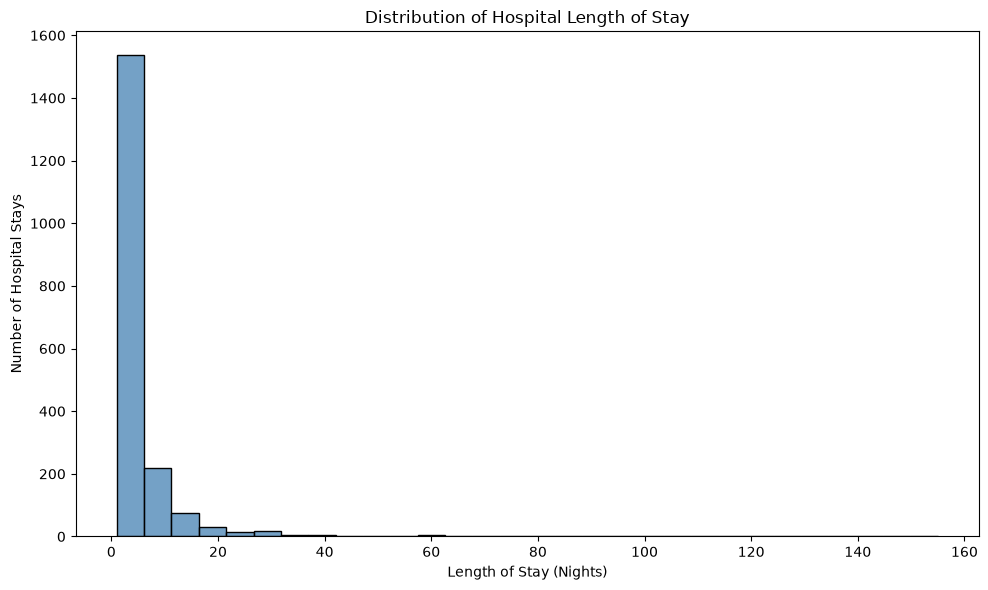

In [3]:
# Histogram for length of stay
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="NUMNIGHX",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Hospital Length of Stay")
plt.xlabel("Length of Stay (Nights)")
plt.ylabel("Number of Hospital Stays")

plt.tight_layout()
plt.show()

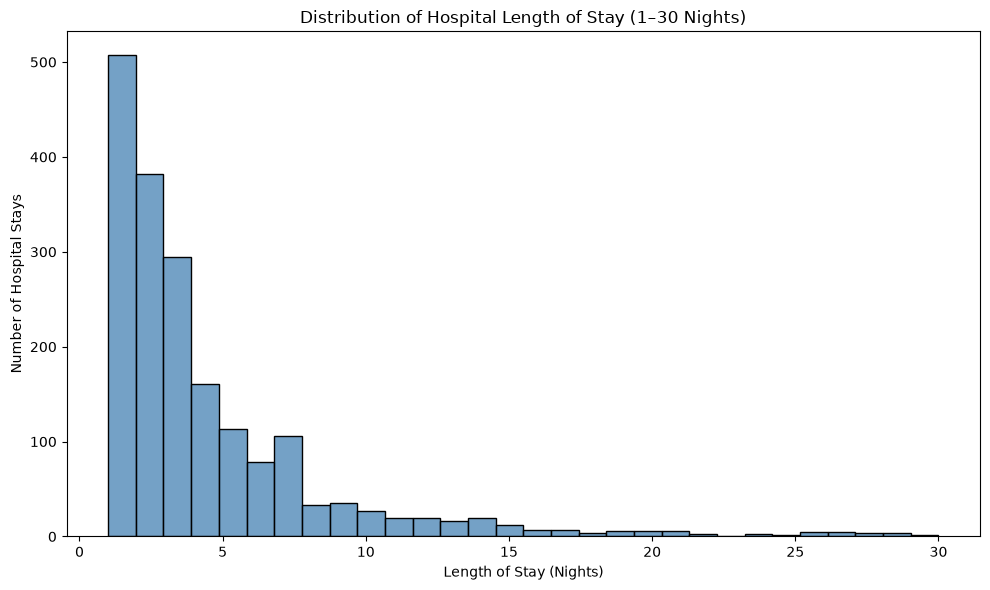

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df[df["NUMNIGHX"] <= 30],
    x="NUMNIGHX",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Hospital Length of Stay (1–30 Nights)")
plt.xlabel("Length of Stay (Nights)")
plt.ylabel("Number of Hospital Stays")

plt.tight_layout()
plt.show()

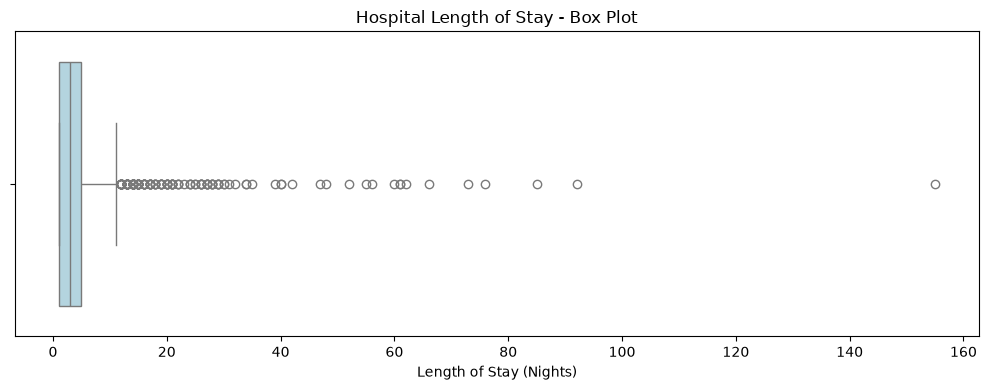

In [4]:
# Box plot for length of stay
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="NUMNIGHX",
    color="lightblue"
)

plt.title("Hospital Length of Stay - Box Plot")
plt.xlabel("Length of Stay (Nights)")

plt.tight_layout()
plt.show()

In [5]:
Q1 = df["NUMNIGHX"].quantile(0.25)
Q3 = df["NUMNIGHX"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = df[df["NUMNIGHX"] > upper_bound]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier threshold:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:",
      round(len(outliers) / len(df) * 100, 2), "%")

Q1: 1.0
Q3: 5.0
IQR: 4.0
Upper outlier threshold: 11.0
Number of potential outliers: 156
Percentage of potential outliers: 8.16 %


Descriptive statistics, histograms, and box plots were utilized to examine the distribution of hospital length of stay. Out of the 1,912 inpatient stays, the minimum length of stay was 1 night and the maximum was 155 nights. On average, patients spent approximately 4.88 nights in the hospital while the median length of stay was 3 nights. The distribution was positively skewed, or right skewed, which indicates that most hospitalizations were relatively short. 

The interquartile range (IQR) method showed that hospitalizations exceeding 11 nights were considered potential outliers. There's a total of 156 records (8.16%) that exceed this threshold, with the longest length of stay being 155 nights. Since extended hospital stays may repreesnt legitimate cases relevant to the research question, those outliers were retained. 

## Age vs Length of Stay and Visuals

In [8]:
age_bins = [0, 17, 34, 49, 64, 120]
age_labels = ["0–17", "18–34", "35–49", "50–64", "65+"]

df["Age_Group"] = pd.cut(
    df["AGE24X"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_summary = (
    df.groupby("Age_Group", observed=True)["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(age_summary)

           count  mean  median
Age_Group                     
0–17         101  3.61     2.0
18–34        194  3.81     2.0
35–49        198  5.04     3.0
50–64        384  4.55     3.0
65+          943  5.11     3.0


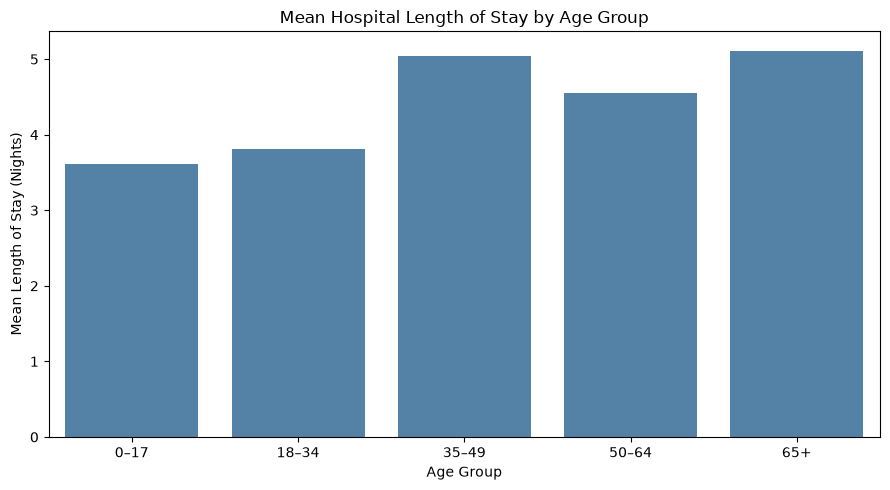

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Age_Group",
    y="NUMNIGHX",
    estimator="mean",
    errorbar=None,
    color="steelblue"
)

plt.title("Mean Hospital Length of Stay by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Mean Length of Stay (Nights)")

plt.tight_layout()
plt.show()

## Sex vs Length of Stay and Visuals

In [11]:
sex_summary = (
    df.groupby("SEX")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

sex_summary.index = sex_summary.index.map({
    1: "Male",
    2: "Female"
})

print(sex_summary)

        count  mean  median
SEX                        
Male      796  5.23     3.0
Female   1116  4.63     3.0


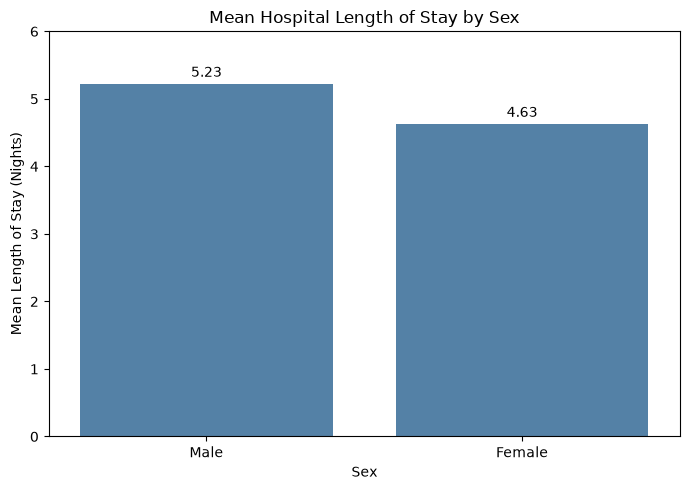

In [12]:
sex_plot = (
    df.groupby("SEX")["NUMNIGHX"]
    .mean()
    .rename(index={1: "Male", 2: "Female"})
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=sex_plot.index,
    y=sex_plot.values,
    color="steelblue"
)

for i, value in enumerate(sex_plot.values):
    ax.text(i, value + 0.1, f"{value:.2f}", ha="center")

plt.title("Mean Hospital Length of Stay by Sex")
plt.xlabel("Sex")
plt.ylabel("Mean Length of Stay (Nights)")
plt.ylim(0, 6)

plt.tight_layout()
plt.show()

## Emergency Room vs Length of Stay and Visuals

In [13]:
er_summary = (
    df.groupby("EMERROOM")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

er_summary.index = er_summary.index.map({
    1: "Yes",
    2: "No"
})

print(er_summary)

          count  mean  median
EMERROOM                     
Yes        1020  4.81     3.0
No          892  4.96     2.0


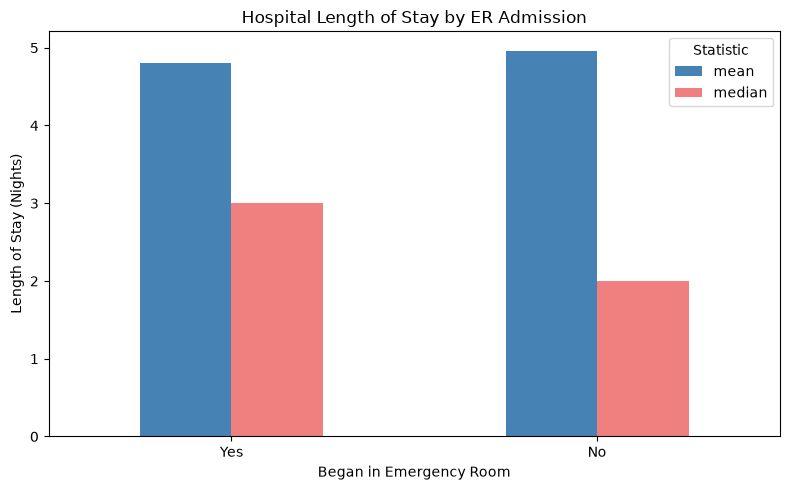

In [14]:
er_plot = (
    df.groupby("EMERROOM")["NUMNIGHX"]
    .agg(["mean", "median"])
    .rename(index={1: "Yes", 2: "No"})
)

er_plot.index.name = "Began in ER"

ax = er_plot.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "lightcoral"],
    rot=0
)

plt.title("Hospital Length of Stay by ER Admission")
plt.xlabel("Began in Emergency Room")
plt.ylabel("Length of Stay (Nights)")
plt.legend(title="Statistic")

plt.tight_layout()
plt.show()

## Surgical Procedures vs Length of Stay

In [15]:
surgery_summary = (
    df.groupby("ANYOPER")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

surgery_summary.index = surgery_summary.index.map({
    1: "Yes",
    2: "No"
})

print(surgery_summary)

         count  mean  median
ANYOPER                     
Yes        716  4.89     3.0
No        1177  4.85     3.0


## Patient Health Status vs Length of Stay

In [16]:
health_summary = (
    df.groupby("RTHLTH53")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

health_summary.index = health_summary.index.map({
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor"
})

print(health_summary)

           count  mean  median
RTHLTH53                      
Excellent    130  3.16     2.0
Very Good    355  3.54     2.0
Good         508  3.99     2.0
Fair         515  5.27     3.0
Poor         265  7.22     3.0


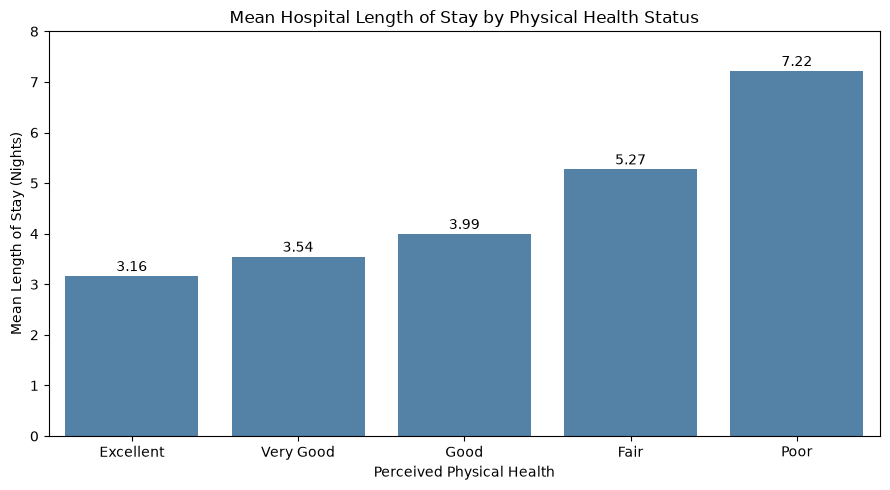

In [17]:
health_order = ["Excellent", "Very Good", "Good", "Fair", "Poor"]

health_plot = (
    df.groupby("RTHLTH53")["NUMNIGHX"]
    .mean()
    .rename(index={
        1: "Excellent",
        2: "Very Good",
        3: "Good",
        4: "Fair",
        5: "Poor"
    })
    .reindex(health_order)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=health_plot.index,
    y=health_plot.values,
    color="steelblue"
)

for i, value in enumerate(health_plot.values):
    ax.text(i, value + 0.1, f"{value:.2f}", ha="center")

plt.title("Mean Hospital Length of Stay by Physical Health Status")
plt.xlabel("Perceived Physical Health")
plt.ylabel("Mean Length of Stay (Nights)")
plt.ylim(0, 8)

plt.tight_layout()
plt.show()

## Mental Health Status vs Length of Stay

In [18]:
mental_health_summary = (
    df.groupby("MNHLTH53")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

mental_health_summary.index = mental_health_summary.index.map({
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor"
})

print(mental_health_summary)

           count  mean  median
MNHLTH53                      
Excellent    283  3.00     2.0
Very Good    421  3.87     2.0
Good         600  4.96     3.0
Fair         346  5.35     3.0
Poor         122  8.34     3.0


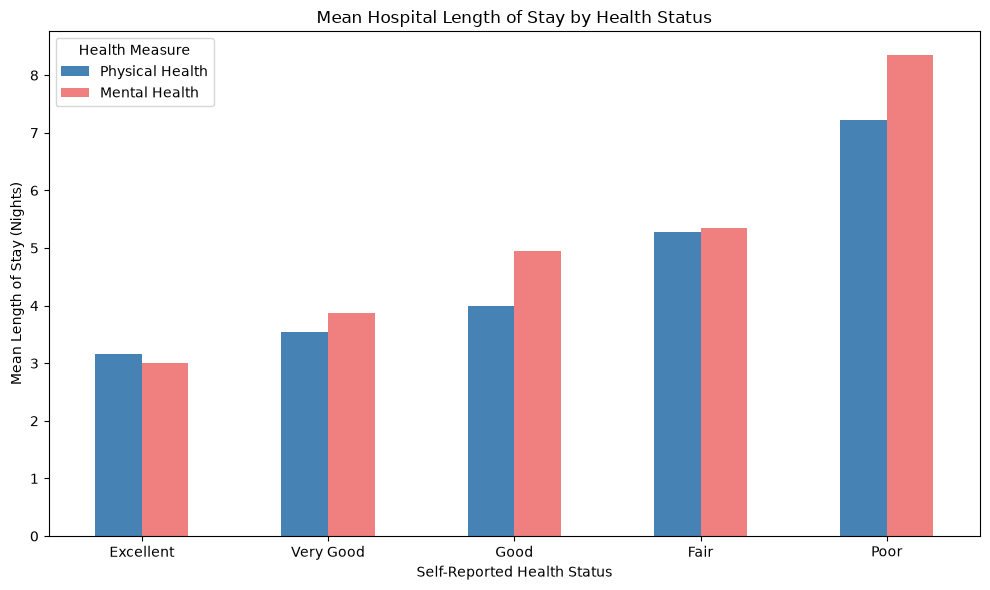

In [20]:
# Combined chart to compare both health variables
health_labels = {
    1: "Excellent",
    2: "Very Good",
    3: "Good",
    4: "Fair",
    5: "Poor"
}

physical = df.groupby("RTHLTH53")["NUMNIGHX"].mean()
mental = df.groupby("MNHLTH53")["NUMNIGHX"].mean()

health_comparison = pd.DataFrame({
    "Physical Health": physical,
    "Mental Health": mental
})

health_comparison.index = health_comparison.index.map(health_labels)

health_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "lightcoral"],
    rot=0
)

plt.title("Mean Hospital Length of Stay by Health Status")
plt.xlabel("Self-Reported Health Status")
plt.ylabel("Mean Length of Stay (Nights)")
plt.legend(title="Health Measure")

plt.tight_layout()
plt.show()

## Chronic Health Conditions vs Length of Stay

In [21]:
diabetes_summary = (
    df.groupby("DIABDX_M18")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

diabetes_summary.index = diabetes_summary.index.map({
    1: "Yes",
    2: "No"
})

print(diabetes_summary)

            count  mean  median
DIABDX_M18                     
Yes           573  5.87     3.0
No           1324  4.46     2.5


In [23]:
conditions = {
    "Diabetes": "DIABDX_M18",
    "High Blood Pressure": "HIBPDX",
    "Coronary Heart Disease": "CHDDX",
    "Stroke": "STRKDX",
    "Asthma": "ASTHDX"
}

results = []

for condition, column in conditions.items():
    summary = df.groupby(column)["NUMNIGHX"].agg(
        ["count", "mean", "median"]
    )

    for code, label in [(1, "Yes"), (2, "No")]:
        if code in summary.index:
            results.append({
                "Condition": condition,
                "Diagnosis": label,
                "Count": int(summary.loc[code, "count"]),
                "Mean LOS": round(summary.loc[code, "mean"], 2),
                "Median LOS": round(summary.loc[code, "median"], 2)
            })

conditions_summary = pd.DataFrame(results)

print(conditions_summary.to_string(index=False))

             Condition Diagnosis  Count  Mean LOS  Median LOS
              Diabetes       Yes    573      5.87         3.0
              Diabetes        No   1324      4.46         2.5
   High Blood Pressure       Yes   1112      5.16         3.0
   High Blood Pressure        No    675      4.55         3.0
Coronary Heart Disease       Yes    371      5.50         3.0
Coronary Heart Disease        No   1415      4.78         3.0
                Stroke       Yes    256      5.62         3.0
                Stroke        No   1532      4.82         3.0
                Asthma       Yes    415      4.80         3.0
                Asthma        No   1482      4.91         3.0


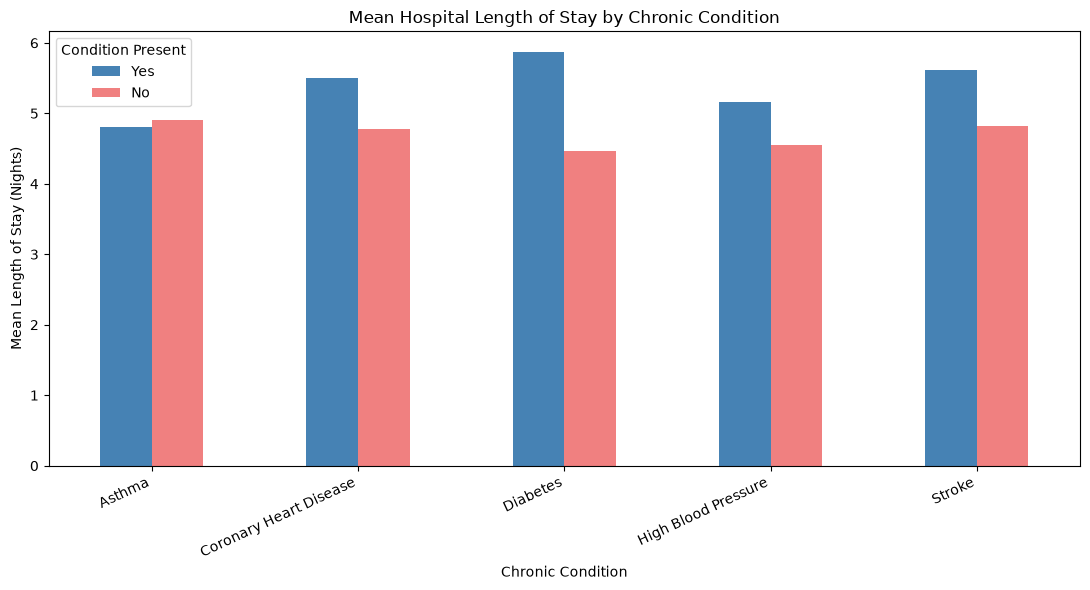

In [24]:
condition_plot = conditions_summary.pivot(
    index="Condition",
    columns="Diagnosis",
    values="Mean LOS"
)

condition_plot = condition_plot[["Yes", "No"]]

ax = condition_plot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "lightcoral"],
    rot=25
)

plt.title("Mean Hospital Length of Stay by Chronic Condition")
plt.xlabel("Chronic Condition")
plt.ylabel("Mean Length of Stay (Nights)")
plt.legend(title="Condition Present")
plt.xticks(ha="right")

plt.tight_layout()
plt.show()

## Insurance Coverage vs Length of Stay

In [25]:
insurance_summary = (
    df.groupby("INSCOV24")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

insurance_summary.index = insurance_summary.index.map({
    1: "Any Private",
    2: "Public Only",
    3: "Uninsured"
})

print(insurance_summary)

             count  mean  median
INSCOV24                        
Any Private    791  4.33     3.0
Public Only   1097  5.28     3.0
Uninsured       24  4.67     3.5


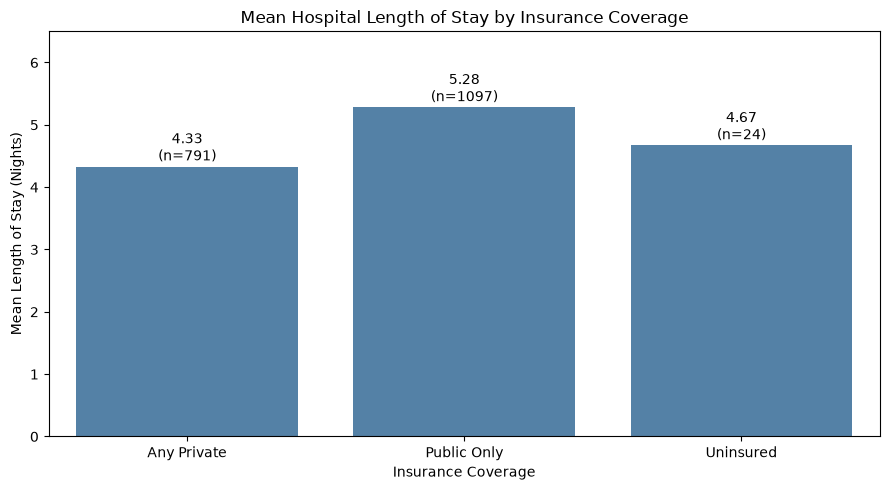

In [26]:
insurance_plot = insurance_summary.copy()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=insurance_plot.index,
    y=insurance_plot["mean"],
    color="steelblue"
)

for i, (mean, count) in enumerate(
    zip(insurance_plot["mean"], insurance_plot["count"])
):
    ax.text(
        i,
        mean + 0.1,
        f"{mean:.2f}\n(n={count})",
        ha="center"
    )

plt.title("Mean Hospital Length of Stay by Insurance Coverage")
plt.xlabel("Insurance Coverage")
plt.ylabel("Mean Length of Stay (Nights)")
plt.ylim(0, 6.5)

plt.tight_layout()
plt.show()

## Geographic Region vs Length of Stay

In [27]:
region_summary = (
    df.groupby("REGION24")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

region_summary.index = region_summary.index.map({
    1: "Northeast",
    2: "Midwest",
    3: "South",
    4: "West"
})

print(region_summary)

           count  mean  median
REGION24                      
Northeast    295  5.37     3.0
Midwest      426  4.94     3.0
South        748  4.82     3.0
West         351  3.90     2.0


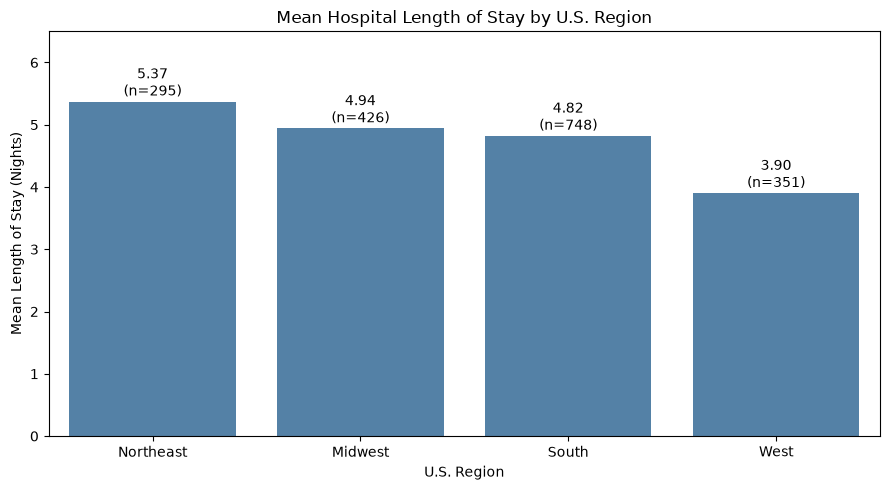

In [28]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=region_summary.index,
    y=region_summary["mean"],
    color="steelblue"
)

for i, (mean, count) in enumerate(
    zip(region_summary["mean"], region_summary["count"])
):
    ax.text(
        i,
        mean + 0.1,
        f"{mean:.2f}\n(n={count})",
        ha="center"
    )

plt.title("Mean Hospital Length of Stay by U.S. Region")
plt.xlabel("U.S. Region")
plt.ylabel("Mean Length of Stay (Nights)")
plt.ylim(0, 6.5)

plt.tight_layout()
plt.show()

## Reason for Hospitalization vs Length of Stay

In [30]:
reason_summary = (
    df.groupby("RSNINHOS")["NUMNIGHX"]
    .agg(["count", "mean", "median"])
    .round(2)
)

reason_summary.index = reason_summary.index.map({
    1: "Surgery/Operation",
    2: "Treatment/Therapy",
    3: "Diagnostic Tests",
    4: "Childbirth (Mother)",
    5: "Birth (Baby)",
    6: "Pregnancy Complications",
    91: "Other"
})

print(reason_summary)

                         count  mean  median
RSNINHOS                                    
Surgery/Operation          561  4.24     2.0
Treatment/Therapy          756  5.85     3.0
Diagnostic Tests           275  3.37     2.0
Childbirth (Mother)        115  2.62     2.0
Birth (Baby)                 9  5.67     2.0
Pregnancy Complications     24  6.62     1.5
Other                      149  6.51     3.0


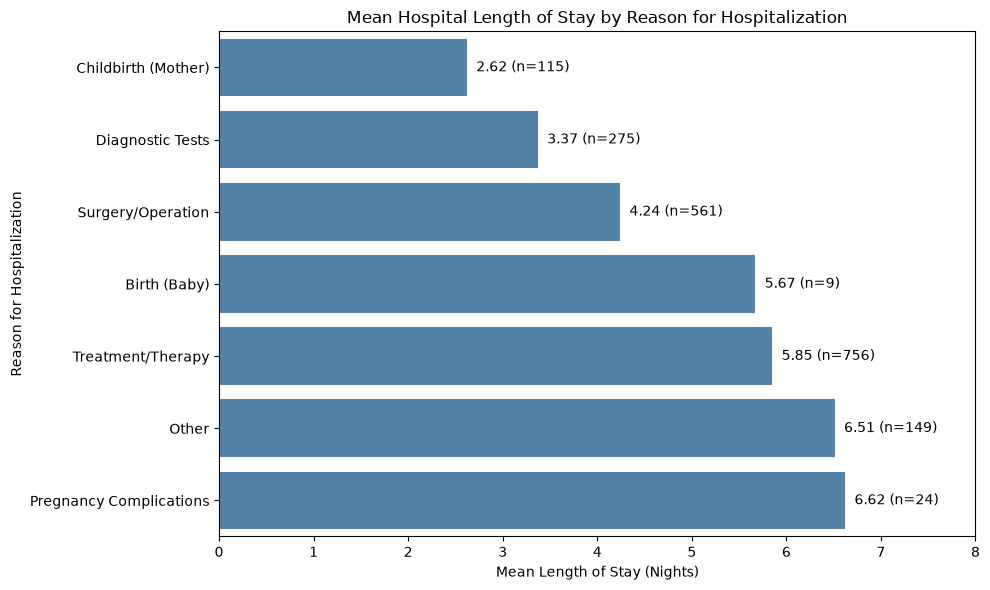

In [31]:
reason_plot = reason_summary.sort_values("mean")

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=reason_plot["mean"],
    y=reason_plot.index,
    color="steelblue"
)

for i, (mean, count) in enumerate(
    zip(reason_plot["mean"], reason_plot["count"])
):
    ax.text(
        mean + 0.1,
        i,
        f"{mean:.2f} (n={count})",
        va="center"
    )

plt.title("Mean Hospital Length of Stay by Reason for Hospitalization")
plt.xlabel("Mean Length of Stay (Nights)")
plt.ylabel("Reason for Hospitalization")
plt.xlim(0, 8)

plt.tight_layout()
plt.show()